# 01 — Dataset Exploration (PPG-DaLiA, Subject S1)

**Goal of this notebook:** load ONE subject's synchronized data, verify its structure,
and visually inspect PPG, accelerometer, and ground-truth HR signals before any
processing is applied.

We deliberately use only S1 here — Phase 1 is about understanding the data, not
processing the full dataset (that comes in later phases).


In [1]:
import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

DATA_ROOT = Path("../data/raw/PPG_FieldStudy")
SUBJECT = 1


Matplotlib is building the font cache; this may take a moment.


## 1. Load the subject file

`SX.pkl` is a Python dictionary containing all synchronized signals, ground-truth HR
labels, activity labels, and metadata for one subject. Structure confirmed directly
from the dataset's own `PPG_FieldStudy_readme.pdf`:

- `signal -> wrist -> BVP`: PPG signal, 64 Hz
- `signal -> wrist -> ACC`: wrist accelerometer (X, Y, Z), 32 Hz, units of 1/64 g
- `signal -> chest -> ECG`: chest ECG, 700 Hz (ground-truth source; EDA/EMG/Temp under
  `chest` are dummy data per the readme and are ignored)
- `label`: ground-truth HR, mean ECG-derived instantaneous HR per 8s window, shifted 2s
- `activity`: activity ID (0-8), resampled to 4 Hz
- `rpeaks`: indices of detected ECG R-peaks


In [2]:
def load_subject(subject_id: int, data_root: Path) -> dict:
    """Load one subject's synchronized PPG-DaLiA data from SX.pkl."""
    pkl_path = data_root / f"S{subject_id}" / f"S{subject_id}.pkl"
    with open(pkl_path, "rb") as f:
        data = pickle.load(f, encoding="latin1")
    return data


d = load_subject(SUBJECT, DATA_ROOT)
print("Top-level keys:", list(d.keys()))


Top-level keys: ['rpeaks', 'signal', 'label', 'activity', 'questionnaire', 'subject']


## 2. Inspect shapes and sampling information

In [3]:
bvp = d["signal"]["wrist"]["BVP"].flatten()
acc = d["signal"]["wrist"]["ACC"]
acc_g = acc / 64.0
hr_label = d["label"].flatten()
activity = d["activity"].flatten()

FS_BVP = 64
FS_ACC = 32
FS_ACTIVITY = 4
WINDOW_LEN_S = 8
WINDOW_SHIFT_S = 2

print(f"BVP:      {bvp.shape}, {bvp.shape[0]/FS_BVP:.1f} s at {FS_BVP} Hz")
print(f"ACC:      {acc.shape}, {acc.shape[0]/FS_ACC:.1f} s at {FS_ACC} Hz")
print(f"HR label: {hr_label.shape} windows (8s window / 2s shift)")
print(f"Activity: {activity.shape}, {activity.shape[0]/FS_ACTIVITY:.1f} s at {FS_ACTIVITY} Hz")

duration_s = bvp.shape[0] / FS_BVP
expected_windows = int((duration_s - WINDOW_LEN_S) / WINDOW_SHIFT_S) + 1
print(f"\nExpected HR windows from duration: {expected_windows}, actual: {hr_label.shape[0]}")


BVP:      (589568,), 9212.0 s at 64 Hz
ACC:      (294784, 3), 9212.0 s at 32 Hz
HR label: (4603,) windows (8s window / 2s shift)
Activity: (36848,), 9212.0 s at 4 Hz

Expected HR windows from duration: 4603, actual: 4603


## 3. Plot raw PPG (BVP)

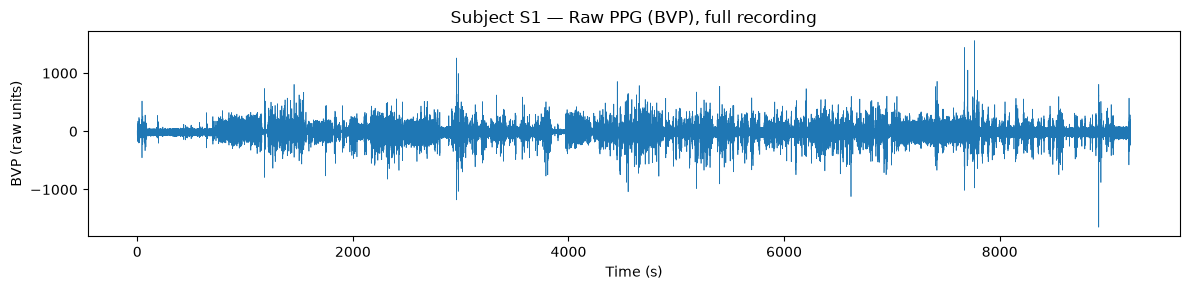

In [4]:
t_bvp = np.arange(len(bvp)) / FS_BVP

fig, ax1 = plt.subplots(figsize=(12, 3))
ax1.plot(t_bvp, bvp, linewidth=0.5)
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("BVP (raw units)")
ax1.set_title(f"Subject S{SUBJECT} — Raw PPG (BVP), full recording")
plt.tight_layout()
plt.show()


## 4. Plot wrist accelerometer — Ax, Ay, Az separately

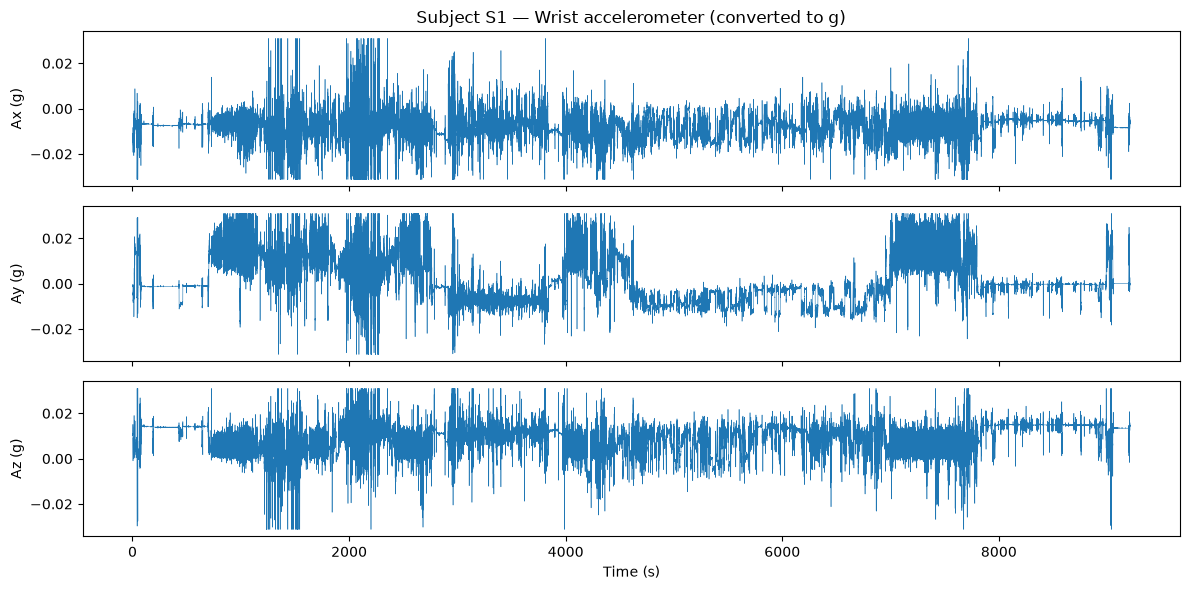

In [5]:
t_acc = np.arange(acc_g.shape[0]) / FS_ACC

fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
labels = ["Ax", "Ay", "Az"]
for i in range(3):
    axes[i].plot(t_acc, acc_g[:, i], linewidth=0.4)
    axes[i].set_ylabel(f"{labels[i]} (g)")
axes[-1].set_xlabel("Time (s)")
axes[0].set_title(f"Subject S{SUBJECT} — Wrist accelerometer (converted to g)")
plt.tight_layout()
plt.show()


## 5. Plot ground-truth HR

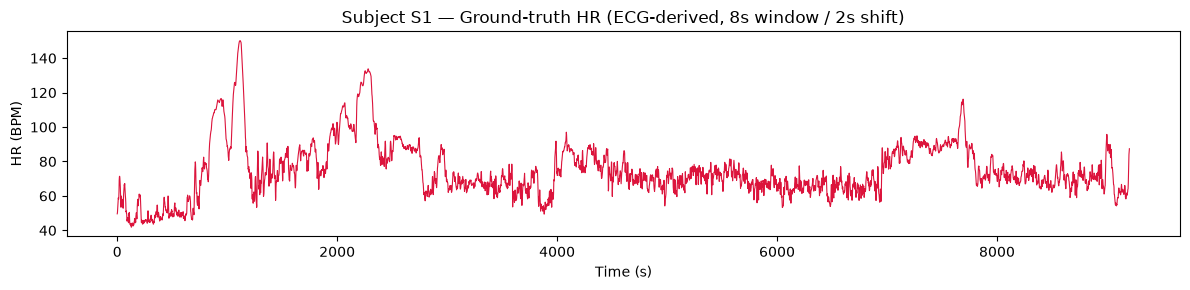

In [6]:
t_hr = np.arange(len(hr_label)) * WINDOW_SHIFT_S

fig, ax1 = plt.subplots(figsize=(12, 3))
ax1.plot(t_hr, hr_label, linewidth=0.8, color="crimson")
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("HR (BPM)")
ax1.set_title(f"Subject S{SUBJECT} — Ground-truth HR (ECG-derived, 8s window / 2s shift)")
plt.tight_layout()
plt.show()


## 6. Synchronized time window — the key plot for this project

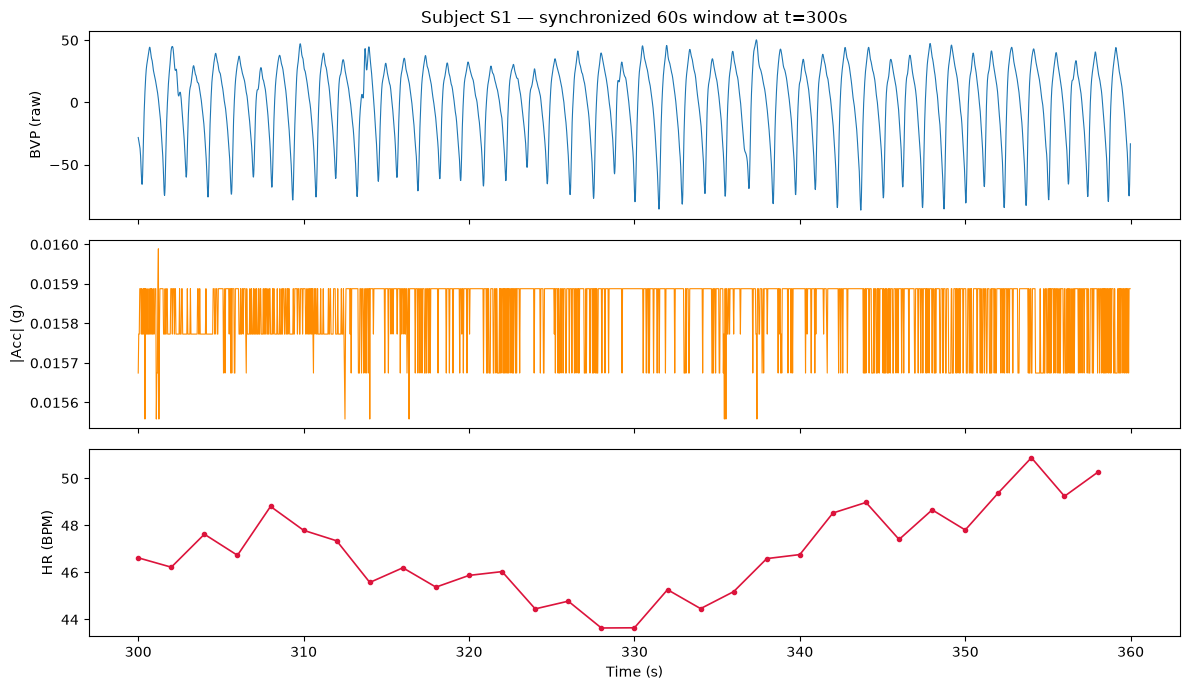

Activity ID(s) during this window: [1.]
0=transient 1=sitting 2=stairs 3=table_soccer 4=cycling 5=driving 6=lunch 7=walking 8=working


In [17]:
acc_mag = np.sqrt((acc_g ** 2).sum(axis=1))

WINDOW_START_S = 300
WINDOW_DUR_S = 60

bvp_mask = (t_bvp >= WINDOW_START_S) & (t_bvp < WINDOW_START_S + WINDOW_DUR_S)
acc_mask = (t_acc >= WINDOW_START_S) & (t_acc < WINDOW_START_S + WINDOW_DUR_S)
hr_mask = (t_hr >= WINDOW_START_S) & (t_hr < WINDOW_START_S + WINDOW_DUR_S)

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)

axes[0].plot(t_bvp[bvp_mask], bvp[bvp_mask], linewidth=0.8)
axes[0].set_ylabel("BVP (raw)")
axes[0].set_title(f"Subject S{SUBJECT} — synchronized {WINDOW_DUR_S}s window at t={WINDOW_START_S}s")

axes[1].plot(t_acc[acc_mask], acc_mag[acc_mask], linewidth=0.8, color="darkorange")
axes[1].set_ylabel("|Acc| (g)")

axes[2].plot(t_hr[hr_mask], hr_label[hr_mask], linewidth=1.2, color="crimson", marker="o", markersize=3)
axes[2].set_ylabel("HR (BPM)")
axes[2].set_xlabel("Time (s)")

plt.tight_layout()
plt.show()

act_mask = (np.arange(len(activity)) / FS_ACTIVITY >= WINDOW_START_S) & \
           (np.arange(len(activity)) / FS_ACTIVITY < WINDOW_START_S + WINDOW_DUR_S)
unique_acts = np.unique(activity[act_mask])
print(f"Activity ID(s) during this window: {unique_acts}")
print("0=transient 1=sitting 2=stairs 3=table_soccer 4=cycling 5=driving 6=lunch 7=walking 8=working")


In [10]:
def find_activity_windows(activity, fs_activity, target_id, min_duration_s=30):
    """Find contiguous stretches of a given activity ID, at least min_duration_s long."""
    is_target = (activity == target_id).astype(int)
    changes = np.diff(is_target, prepend=0, append=0)
    starts = np.where(changes == 1)[0]
    ends = np.where(changes == -1)[0]

    windows = []
    for s, e in zip(starts, ends):
        duration_s = (e - s) / fs_activity
        if duration_s >= min_duration_s:
            start_s = s / fs_activity
            windows.append((start_s, duration_s))
    return windows

# Activity IDs: 1=sitting, 4=cycling, 7=walking
for act_id, name in [(1, "sitting"), (7, "walking"), (4, "cycling")]:
    windows = find_activity_windows(activity, FS_ACTIVITY, act_id, min_duration_s=30)
    print(f"{name} (ID {act_id}): {len(windows)} segment(s) >= 30s")
    for start_s, dur_s in windows[:3]:
        print(f"    starts at t={start_s:.0f}s, lasts {dur_s:.0f}s")

sitting (ID 1): 1 segment(s) >= 30s
    starts at t=90s, lasts 700s
walking (ID 7): 1 segment(s) >= 30s
    starts at t=6951s, lasts 754s
cycling (ID 4): 1 segment(s) >= 30s
    starts at t=1918s, lasts 412s


In [11]:
WINDOW_START_S = <a printed walking start_s + 15>

SyntaxError: invalid syntax (1928360545.py, line 1)

## 7. Observations (fill in after running)

- Does the chosen 60s window fall during a low-motion or high-motion activity?
- Does the BVP waveform look clean or noisy/irregular in this window?
- Does the accelerometer magnitude spike align with any visible change in BVP shape?
- Does the ground-truth HR look smooth or jump erratically?

Try re-running Section 6 with a different `WINDOW_START_S` during a high-motion
activity (e.g. cycling=4 or stairs=2) and compare against this baseline window.
